# Linear and Polynomial Regression

1. Ordinary least squares derived by hand (closed-form β₀, β₁) and checked against `LinearRegression`.
2. A degree-5 polynomial pipeline on `y = 12·sin(x) + 0.5x² + 2x + 5` plus noise.
3. `GridSearchCV` over polynomial degree 1–19 with 5-fold CV: best degree **7**, test MSE **3.50**.

### (b)

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

In [2]:
np.random.seed(42)
x = np.linspace(1,10,100)
y = -5*x + 15 + np.random.normal(0,1,100)

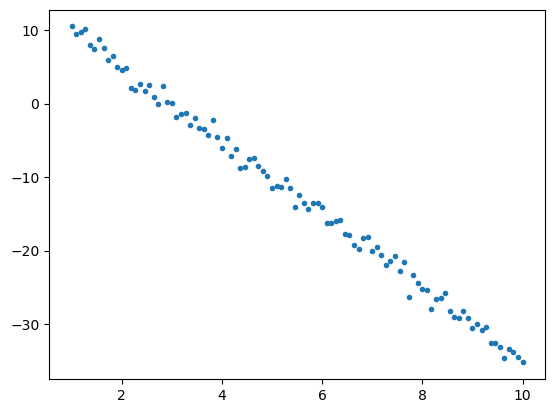

In [3]:
plt.plot(x,y,'.')

### (c)

least squares line: y = 14.811861293326373 + -4.984674147403721x
SSR = 81.49047134980785


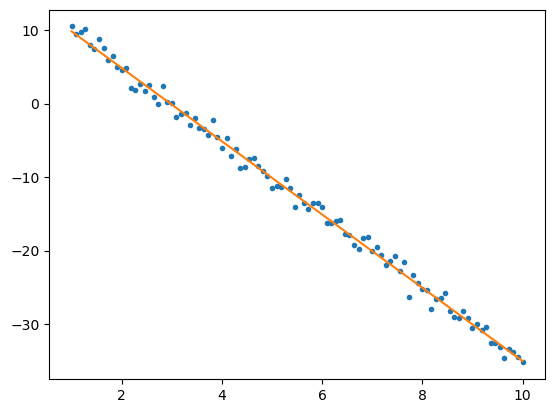

In [4]:
Beta_1 = (np.sum(x*y)-100*(np.mean(x)*np.mean(y)))/(np.sum(x**2)-100*np.mean(x)**2)
Beta_0 = np.mean(y)-Beta_1*np.mean(x)
y_pred = Beta_0+Beta_1*x
ssr = sum((y - y_pred)**2)
plt.plot(x,y,'.')
plt.plot(x,y_pred)
print(f"least squares line: y = {Beta_0} + {Beta_1}x")
print(f"SSR = {ssr}")

### (d)

In [5]:
reg = LinearRegression()
X_rs = np.array(x).reshape(-1, 1)
reg.fit(X_rs,y)
print(f"Beta_1 = {reg.coef_:}")
print(f"Beta_0 = {reg.intercept_:} ")

Beta_1 = [-4.98467415]
Beta_0 = 14.811861293326345 


# 2.

### (a)

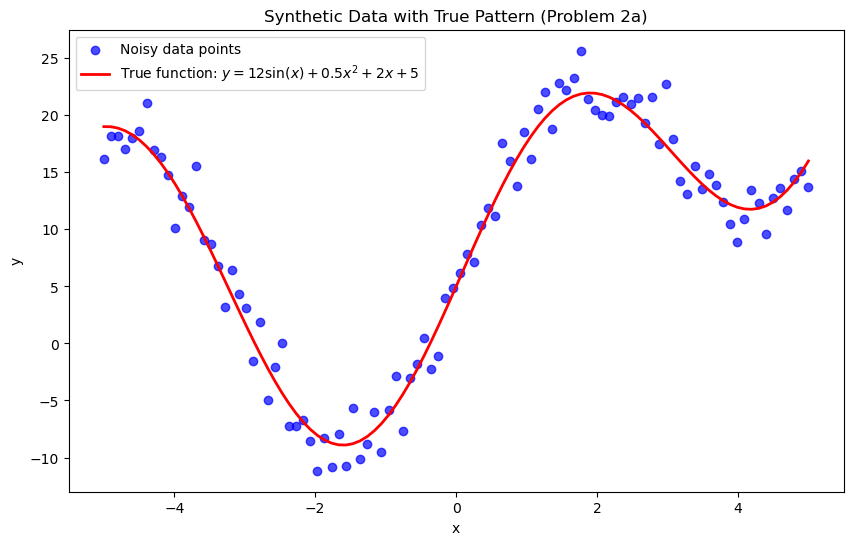

In [6]:
x = np.linspace(-5, 5, 100)
y_true = 12*np.sin(x)+0.5*x**2+2*x+5
y_noisy = y_true+np.random.normal(0,2,size=len(x))
plt.figure(figsize=(10, 6))

plt.scatter(x, y_noisy, alpha=0.7, label='Noisy data points', color='blue')
plt.plot(x, y_true, 'r-', linewidth=2, label='True function: $y = 12\\sin(x) + 0.5x^2 + 2x + 5$')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Synthetic Data with True Pattern (Problem 2a)')
plt.legend()
plt.show()

### (b)

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

pipeline_1 = Pipeline([('poly_features', PolynomialFeatures(degree=5)),  ('linear_regression', LinearRegression())])

### (c)

In [8]:
X = np.array(x).reshape(-1, 1)  
y = y_noisy  

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [9]:
pipeline_1.fit(X_train, y_train)

Pipeline(steps=[('poly_features', PolynomialFeatures(degree=5)),
                ('linear_regression', LinearRegression())])

In [10]:
from sklearn.metrics import mean_squared_error

y_test_pred = pipeline_1.predict(X_test)
mse_test = mean_squared_error(y_test, y_test_pred)

In [11]:
print(f"test MSE: {mse_test}")

test MSE: 4.295222161412963


### (d)

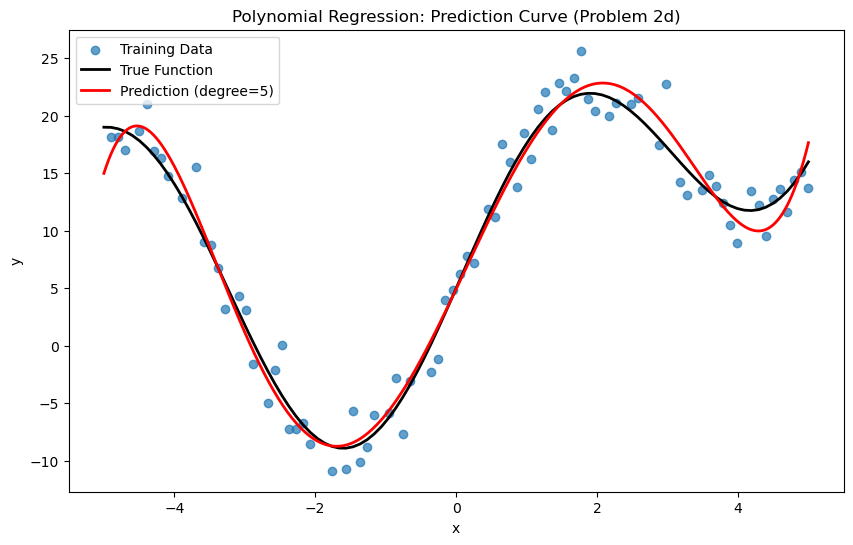

In [12]:
x_dense_1 = np.linspace(-5, 5, 300).reshape(-1, 1)
y_pred_dense_1 = pipeline_1.predict(x_dense_1)

plt.figure(figsize=(10, 6))
plt.scatter(X_train, y_train, alpha=0.7, label='Training Data')
plt.plot(x, y_true, 'k-', linewidth=2, label='True Function')
plt.plot(x_dense_1, y_pred_dense_1, 'r-', linewidth=2, label='Prediction (degree=5)')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Polynomial Regression: Prediction Curve (Problem 2d)')
plt.legend()
plt.show()

# 3.

### (a)

In [13]:
from sklearn.preprocessing import PolynomialFeatures

pipeline_2 = Pipeline([('poly_features', PolynomialFeatures()),('linear_regression', LinearRegression())])

### (b)

In [14]:
from sklearn.model_selection import GridSearchCV
param_grid = {'poly_features__degree': list(range(1, 20))}
grid_search = GridSearchCV(
    pipeline_2, 
    param_grid, 
    cv=5,  
    scoring='neg_mean_squared_error',  
    return_train_score=True  
)
grid_search.fit(X_train, y_train)
results = grid_search.cv_results_

In [15]:
best_degree = grid_search.best_params_['poly_features__degree']

print(f"best degree: {best_degree}")

best_model = grid_search.best_estimator_
y_test_pred = best_model.predict(X_test)
test_mse = mean_squared_error(y_test, y_test_pred)

print(f"test MSE: {test_mse:.4f}")

best degree: 7
test MSE: 3.5011


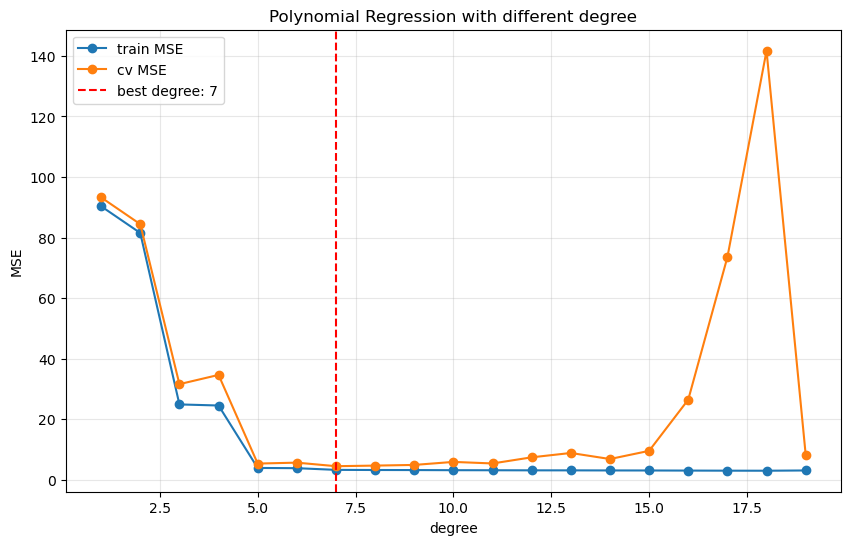

In [16]:
plt.figure(figsize=(10, 6))
degrees = param_grid['poly_features__degree']
test_scores = -results['mean_test_score']  
train_scores = -results['mean_train_score']  

plt.plot(degrees, train_scores, 'o-', label='train MSE')
plt.plot(degrees, test_scores, 'o-', label='cv MSE')
plt.axvline(x=best_degree, color='red', linestyle='--', label=f'best degree: {best_degree}')
plt.xlabel('degree')
plt.ylabel('MSE')
plt.title('Polynomial Regression with different degree')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### (c)

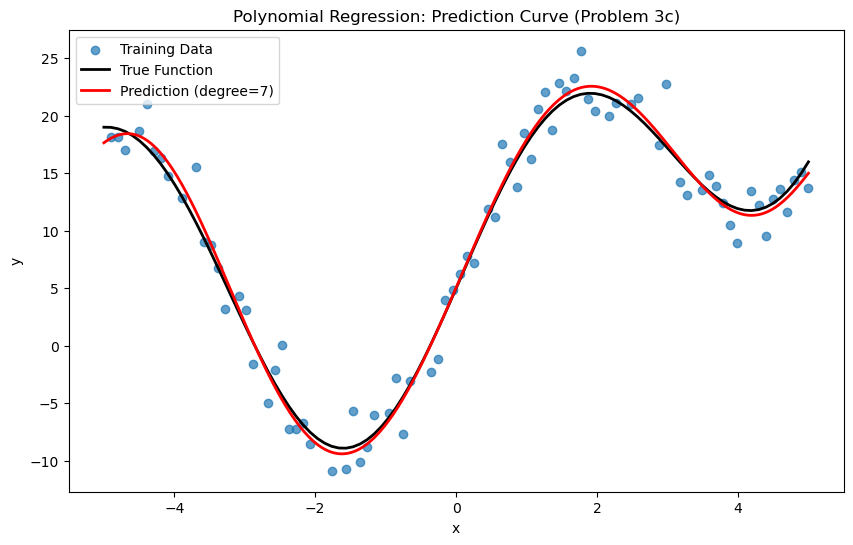

In [17]:
x_dense_2 = np.linspace(-5, 5, 300).reshape(-1, 1)
y_pred_dense_2 = grid_search.predict(x_dense_2)

plt.figure(figsize=(10, 6))
plt.scatter(X_train, y_train, alpha=0.7, label='Training Data')
plt.plot(x, y_true, 'k-', linewidth=2, label='True Function')
plt.plot(x_dense_2, y_pred_dense_2, 'r-', linewidth=2, label='Prediction (degree=7)')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Polynomial Regression: Prediction Curve (Problem 3c)')
plt.legend()
plt.show()